Praktikum 5 - Klasifikasi Citra Siang (day) dan Malam (night).

Pipeline: load gambar -> standarisasi ukuran 1100x600 -> ekstraksi fitur
rata-rata kecerahan (kanal V pada HSV) -> dua pendekatan klasifikasi:
  1) threshold manual pada nilai kecerahan
  2) SVM kernel RBF (default)
Dataset: data/images/{training,test}/{day,night} (images.zip dari jobsheet).

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("citra_siang_malam.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js11-klasifikasi-2\praktikum-5


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import cv2
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.svm import SVC

BASE = Path(__file__).resolve().parent.parent
DATA = BASE / "data" / "images"
OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(exist_ok=True)
TRAIN_DIR, TEST_DIR = DATA / "training", DATA / "test"

[load] train=240 test=160 gambar
[load] contoh shape asli: (458, 800, 3), label=day
[pra] contoh setelah standarisasi: (600, 1100, 3) (h, w, c)


[fitur] train (240, 2), test (160, 2)


[fitur] rata-rata V: day=137.44 night=69.28


[threshold=120] akurasi train = 0.8417
[threshold=120] akurasi test  = 0.8688 (salah 21/160)
[threshold] sapuan nilai threshold:


  thr=80   acc_train=0.7333 acc_test=0.7875


...

  thr=120  acc_train=0.8417 acc_test=0.8688


  thr=130  acc_train=0.7500 acc_test=0.8063


  thr=140  acc_train=0.6875 acc_test=0.7438


  thr=160  acc_train=0.5875 acc_test=0.5687
[svm rbf] akurasi train = 0.8625
[svm rbf] akurasi test  = 0.9000
[svm rbf] classification_report (test):
              precision    recall  f1-score   support

       night     0.8810    0.9250    0.9024        80
         day     0.9211    0.8750    0.8974        80

    accuracy                         0.9000       160
   macro avg     0.9010    0.9000    0.8999       160
weighted avg     0.9010    0.9000    0.8999       160

[svm rbf] confusion matrix (test):
 [[74  6]
 [10 70]]
[tuning] gamma x C (akurasi test):
  gamma=0.001  C=1    acc_test=0.9000
  gamma=0.001  C=10   acc_test=0.9125
  gamma=0.001  C=100  acc_test=0.9250
  gamma=0.01   C=1    acc_test=0.9250
  gamma=0.01   C=10   acc_test=0.9250
  gamma=0.01   C=100  acc_test=0.9250
  gamma=0.1    C=1    acc_test=0.9187
  gamma=0.1    C=10   acc_test=0.9187
  gamma=0.1    C=100  acc_test=0.9250
[tuning] terbaik: gamma=0.001, C=100, acc_test=0.9250


[selesai] praktikum 5, fitur disimpan ke output/fitur_{train,test}.csv


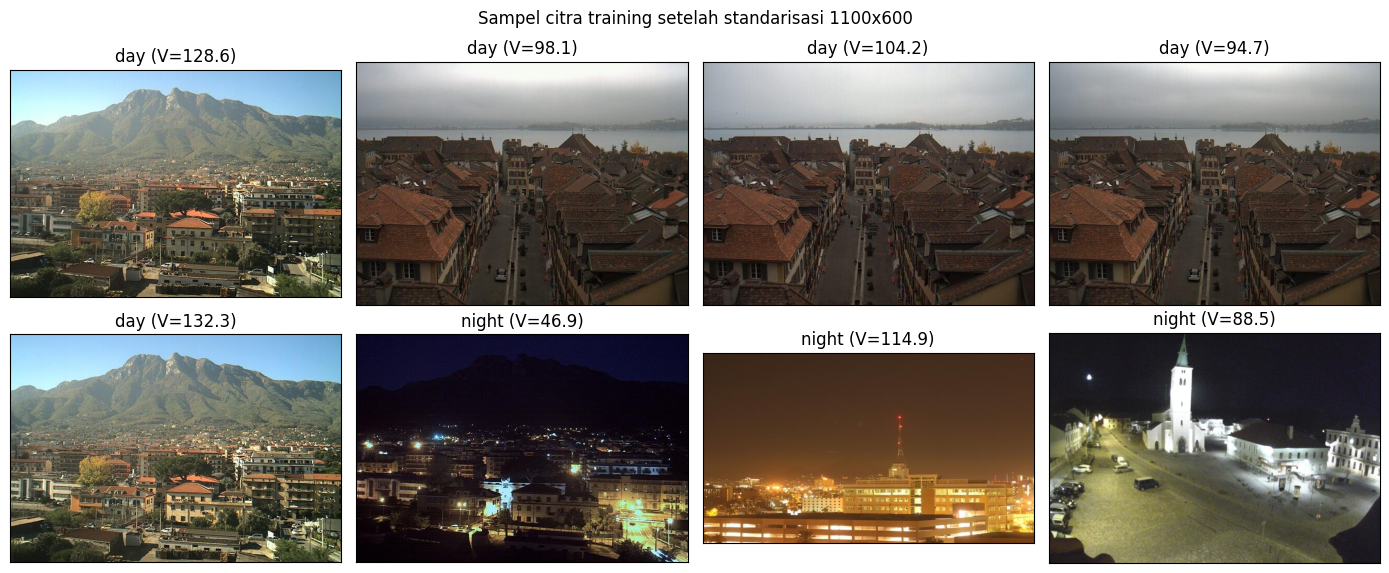

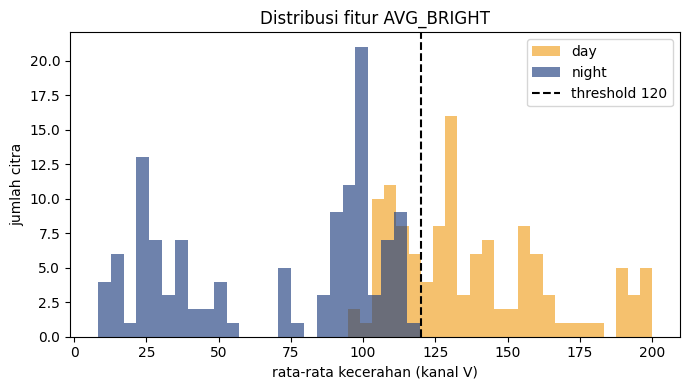

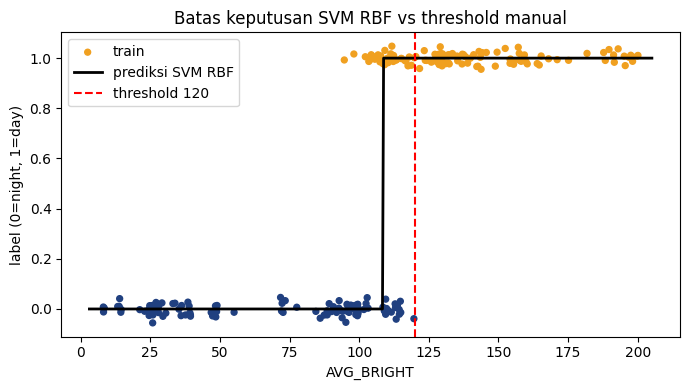

In [3]:
def load_dataset(img_dir):
    """Ambil semua *.jpg dari subfolder (nama folder = label)."""
    img_list = []
    for d in sorted(Path(img_dir).glob("*")):
        if not d.is_dir():
            continue
        for f in sorted(d.glob("*.jpg")):
            img = cv2.imread(str(f))            # BGR
            if img is not None:
                img_list.append((cv2.cvtColor(img, cv2.COLOR_BGR2RGB), d.name))
    return img_list


def standarized_input(image):
    return cv2.resize(image, (1100, 600))


def label_encoder(label):
    return 1 if label == "day" else 0


def avg_brightness(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    return float(np.sum(hsv[:, :, 2])) / (image.shape[0] * image.shape[1])


def predict_label(img, threshold):
    return 1 if avg_brightness(img) > threshold else 0


def evaluate(img_list, threshold):
    miss = [(im, predict_label(im, threshold), lb) for im, lb in img_list
            if predict_label(im, threshold) != lb]
    return (len(img_list) - len(miss)) / len(img_list), miss


def extract_avg_bright_feature(img_list):
    data = np.column_stack(([avg_brightness(im) for im, _ in img_list],
                            [lb for _, lb in img_list]))
    return pd.DataFrame(data, columns=["AVG_BRIGHT", "LABELS"])


train_img = load_dataset(TRAIN_DIR)
test_img = load_dataset(TEST_DIR)
print(f"[load] train={len(train_img)} test={len(test_img)} gambar")
print(f"[load] contoh shape asli: {train_img[0][0].shape}, label={train_img[0][1]}")

# ponytail: avg brightness invarian terhadap ukuran, jadi fitur dihitung dari
# citra asli (cepat) dan cv2.resize 1100x600 hanya dipakai untuk visualisasi.
# Kalau nanti butuh fitur yang bergantung ukuran (mis. citra biner), resize dulu.
train_std = [(im, label_encoder(lb)) for im, lb in train_img]
test_std = [(im, label_encoder(lb)) for im, lb in test_img]
print(f"[pra] contoh setelah standarisasi: {standarized_input(train_std[0][0]).shape} (h, w, c)")
train_df = extract_avg_bright_feature(train_std)
test_df = extract_avg_bright_feature(test_std)
print(f"[fitur] train {train_df.shape}, test {test_df.shape}")

# --- visualisasi sampel ---------------------------------------------------
rng = np.random.RandomState(0)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
idx = rng.choice(len(train_std), 8, replace=False)
for axi, i in zip(axes.flat, idx):
    im, lb = train_std[i]
    axi.imshow(im)
    axi.set(xticks=[], yticks=[],
            title=f"{'day' if lb == 1 else 'night'} (V={avg_brightness(im):.1f})")
fig.suptitle("Sampel citra training setelah standarisasi 1100x600")
fig.tight_layout()
fig.savefig(OUT / "01_sampel_citra.png", dpi=100)

# histogram kecerahan per kelas
fig, ax = plt.subplots(figsize=(7, 4))
for lab, name, col in [(1, "day", "#f0a020"), (0, "night", "#204080")]:
    ax.hist(train_df.loc[train_df.LABELS == lab, "AVG_BRIGHT"], bins=25,
            alpha=0.65, label=name, color=col)
ax.axvline(120, color="k", ls="--", label="threshold 120")
ax.set(xlabel="rata-rata kecerahan (kanal V)", ylabel="jumlah citra",
       title="Distribusi fitur AVG_BRIGHT")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "02_histogram_brightness.png", dpi=110)
print(f"[fitur] rata-rata V: day={train_df[train_df.LABELS==1].AVG_BRIGHT.mean():.2f} "
      f"night={train_df[train_df.LABELS==0].AVG_BRIGHT.mean():.2f}")

# --- 1) klasifikasi threshold ---------------------------------------------
acc_tr_thr, _ = evaluate(train_std, 120)
acc_te_thr, miss_te = evaluate(test_std, 120)
print(f"[threshold=120] akurasi train = {acc_tr_thr:.4f}")
print(f"[threshold=120] akurasi test  = {acc_te_thr:.4f} (salah {len(miss_te)}/{len(test_std)})")

print("[threshold] sapuan nilai threshold:")
for t in [80, 100, 110, 120, 130, 140, 160]:
    a_tr, _ = evaluate(train_std, t)
    a_te, _ = evaluate(test_std, t)
    print(f"  thr={t:<4} acc_train={a_tr:.4f} acc_test={a_te:.4f}")

# --- 2) klasifikasi SVM RBF -----------------------------------------------
X_train = train_df[["AVG_BRIGHT"]].values
y_train = train_df["LABELS"].values.astype(int)
X_test = test_df[["AVG_BRIGHT"]].values
y_test = test_df["LABELS"].values.astype(int)

model = SVC()
model.fit(X_train, y_train)
y_tr_pred = model.predict(X_train)
y_te_pred = model.predict(X_test)
print(f"[svm rbf] akurasi train = {accuracy_score(y_train, y_tr_pred):.4f}")
print(f"[svm rbf] akurasi test  = {accuracy_score(y_test, y_te_pred):.4f}")
print("[svm rbf] classification_report (test):")
print(classification_report(y_test, y_te_pred, target_names=["night", "day"], digits=4))
print("[svm rbf] confusion matrix (test):\n", confusion_matrix(y_test, y_te_pred))

# tuning gamma/C ringkas (grid kecil, tetap cepat)
best = None
print("[tuning] gamma x C (akurasi test):")
for g in [0.001, 0.01, 0.1]:
    for C in [1, 10, 100]:
        m = SVC(kernel="rbf", gamma=g, C=C).fit(X_train, y_train)
        a = accuracy_score(y_test, m.predict(X_test))
        if best is None or a > best[0]:
            best = (a, g, C)
        print(f"  gamma={g:<6} C={C:<4} acc_test={a:.4f}")
print(f"[tuning] terbaik: gamma={best[1]}, C={best[2]}, acc_test={best[0]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
xs = np.linspace(train_df.AVG_BRIGHT.min() - 5, train_df.AVG_BRIGHT.max() + 5, 500)
ax.scatter(X_train, y_train + rng.normal(0, 0.02, len(y_train)), s=18,
           c=["#204080" if v == 0 else "#f0a020" for v in y_train], label="train")
ax.plot(xs, model.predict(xs.reshape(-1, 1)), "k-", lw=2, label="prediksi SVM RBF")
ax.axvline(120, color="r", ls="--", label="threshold 120")
ax.set(xlabel="AVG_BRIGHT", ylabel="label (0=night, 1=day)",
       title="Batas keputusan SVM RBF vs threshold manual")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "03_decision_svm.png", dpi=110)

train_df.to_csv(OUT / "fitur_train.csv", index=False)
test_df.to_csv(OUT / "fitur_test.csv", index=False)
print("[selesai] praktikum 5, fitur disimpan ke output/fitur_{train,test}.csv")